In [1]:
import sys, gc, json, time, pickle
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

APP_ROOT = Path(r"C:\Users\shlok\projects\ddp-llm\comparison-search-app-merged")

for mod in list(sys.modules):
    if mod.startswith("app.") or mod == "app" or mod.startswith("gamma_ckl_engine"):
        del sys.modules[mod]

if str(APP_ROOT) not in sys.path:
    sys.path.insert(0, str(APP_ROOT))

from app import config
from app.embeddings import Embeddings
from app.gamma_ckl_engine import GammaCKLEngine

GAMMA = 5.0
print(f"config.MAX_QUERIES = {config.MAX_QUERIES}")
print(f"GAMMA = {GAMMA}")

config.MAX_QUERIES = 50
GAMMA = 5.0


In [2]:
emb = Embeddings()
print(f"loaded {emb.n} items, dim {emb.X.shape[1]}")
print(f"classes: {emb.classes()}")

TARGET_INDICES = list(range(0, emb.n, 6))
print(f"sampling {len(TARGET_INDICES)} targets")

BASE_SEED = 1000
def target_seed(target_idx):
    return BASE_SEED + target_idx

loaded 600 items, dim 10
classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
sampling 100 targets


In [3]:
baseline_results = []
for target_idx in TARGET_INDICES:
    engine = GammaCKLEngine(
        X=emb.X, gamma=GAMMA,
        target_idx=int(target_idx),
        seed=target_seed(target_idx),
        max_queries=config.MAX_QUERIES,
    )
    while not engine.done:
        i, j = engine.propose_query()
        y = engine.oracle_answer(i, j)
        engine.apply_answer(y, status="clean")
    baseline_results.append({
        "target_idx": target_idx,
        "target_class": emb.label(target_idx),
        "steps": engine.step,
        "stop_reason": engine.stop_reason,
    })

steps = np.array([r["steps"] for r in baseline_results])
print(f"baseline γ-CKL: mean={steps.mean():.1f}, median={np.median(steps):.1f}, p95={np.percentile(steps, 95):.1f}, max={steps.max()}")

baseline γ-CKL: mean=13.5, median=11.0, p95=28.1, max=50


In [4]:
def collect_both_similar_queries(target_indices, threshold=0.6):
    """Run γ-CKL on all targets, find queries where oracle confidence < threshold.
    These are queries where a real user would likely say 'both similar'."""
    findings = []
    for target_idx in target_indices:
        seed = target_seed(target_idx)
        engine = GammaCKLEngine(
            X=emb.X, gamma=GAMMA,
            target_idx=int(target_idx), seed=seed,
            max_queries=config.MAX_QUERIES,
        )
        x_t = emb.X[target_idx]
        while not engine.done:
            i, j = engine.propose_query()
            d_i = np.linalg.norm(emb.X[i] - x_t)
            d_j = np.linalg.norm(emb.X[j] - x_t)
            p_i = (d_j ** GAMMA) / (d_i ** GAMMA + d_j ** GAMMA)
            confidence = max(p_i, 1 - p_i)
            if confidence < threshold:
                findings.append({
                    "target_idx": target_idx,
                    "target_class": emb.label(target_idx),
                    "step": engine.step + 1,
                    "i": i, "class_i": emb.label(i),
                    "j": j, "class_j": emb.label(j),
                    "d_i": d_i, "d_j": d_j,
                    "confidence": confidence,
                })
            y = engine.oracle_answer(i, j)
            engine.apply_answer(y, status="clean")
    return findings

findings = collect_both_similar_queries(TARGET_INDICES, threshold=0.6)
print(f"total 'both similar' queries (confidence < 0.6): {len(findings)}")
print(f"total queries overall: {sum(r['steps'] for r in baseline_results)}")
print(f"fraction: {100*len(findings)/sum(r['steps'] for r in baseline_results):.1f}%")

print(f"\nby target class:")
by_class = defaultdict(int)
for f in findings:
    by_class[f["target_class"]] += 1
for cls in sorted(by_class):
    print(f"  {cls:12s} {by_class[cls]:4d}")

print(f"\nby step position:")
by_step = defaultdict(int)
for f in findings:
    bucket = "1-5" if f["step"] <= 5 else ("6-10" if f["step"] <= 10 else "11+")
    by_step[bucket] += 1
for b in ["1-5", "6-10", "11+"]:
    print(f"  step {b:5s} {by_step[b]:4d}")

total 'both similar' queries (confidence < 0.6): 237
total queries overall: 1348
fraction: 17.6%

by target class:
  buildings      27
  forest         34
  glacier        52
  mountain       52
  sea            56
  street         16

by step position:
  step 1-5     60
  step 6-10    73
  step 11+    104


In [5]:
print("Sample 'both similar' queries (highest ambiguity first):\n")
findings_sorted = sorted(findings, key=lambda f: f["confidence"])
for f in findings_sorted[:10]:
    print(f"target {f['target_idx']} ({f['target_class']}), step {f['step']}: "
          f"i={f['i']} ({f['class_i']}, d={f['d_i']:.2f}) vs j={f['j']} ({f['class_j']}, d={f['d_j']:.2f})  "
          f"confidence={f['confidence']:.3f}")

Sample 'both similar' queries (highest ambiguity first):

target 30 (buildings), step 14: i=63 (buildings, d=4.73) vs j=80 (buildings, d=4.73)  confidence=0.500
target 108 (forest), step 10: i=137 (forest, d=3.13) vs j=197 (forest, d=3.13)  confidence=0.500
target 444 (sea), step 23: i=303 (mountain, d=5.00) vs j=34 (buildings, d=5.00)  confidence=0.501
target 270 (glacier), step 25: i=277 (glacier, d=1.57) vs j=298 (glacier, d=1.57)  confidence=0.501
target 270 (glacier), step 16: i=449 (sea, d=5.44) vs j=511 (street, d=5.43)  confidence=0.501
target 378 (mountain), step 6: i=252 (glacier, d=2.94) vs j=300 (mountain, d=2.94)  confidence=0.502
target 240 (glacier), step 24: i=401 (sea, d=4.07) vs j=406 (sea, d=4.06)  confidence=0.502
target 132 (forest), step 7: i=182 (forest, d=1.66) vs j=116 (forest, d=1.67)  confidence=0.502
target 108 (forest), step 8: i=125 (forest, d=3.14) vs j=128 (forest, d=3.15)  confidence=0.503
target 288 (glacier), step 7: i=204 (glacier, d=1.65) vs j=273 (

target 30 (buildings), step 14, confidence 0.500


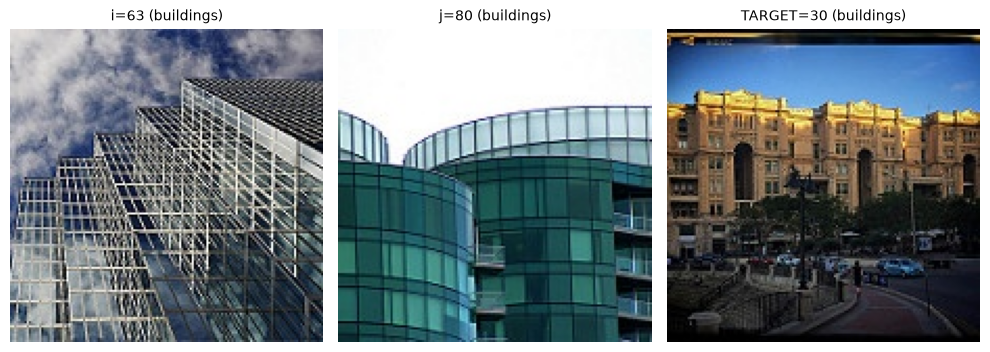

In [6]:
def show_query_vs_target(target_idx, i, j):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    for ax, idx, title in zip(
        axes,
        [i, j, target_idx],
        [f"i={i} ({emb.label(i)})", f"j={j} ({emb.label(j)})", f"TARGET={target_idx} ({emb.label(target_idx)})"],
    ):
        img = Image.open(emb.paths[idx])
        ax.imshow(img)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

f = findings_sorted[0]
print(f"target {f['target_idx']} ({f['target_class']}), step {f['step']}, confidence {f['confidence']:.3f}")
show_query_vs_target(f["target_idx"], f["i"], f["j"])

In [7]:
midpoint_dists = []
avg_dists = []
diff_ratios = []

for f in findings:
    x_i = emb.X[f["i"]]
    x_j = emb.X[f["j"]]
    x_t = emb.X[f["target_idx"]]
    midpoint = (x_i + x_j) / 2
    m = np.linalg.norm(midpoint - x_t)
    d_avg = (f["d_i"] + f["d_j"]) / 2
    d_diff_ratio = abs(f["d_i"] - f["d_j"]) / d_avg
    midpoint_dists.append(m)
    avg_dists.append(d_avg)
    diff_ratios.append(d_diff_ratio)

midpoint_dists = np.array(midpoint_dists)
avg_dists = np.array(avg_dists)
diff_ratios = np.array(diff_ratios)

print(f"For the {len(findings)} 'both similar' queries:")
print(f"  midpoint→target dist:  mean={midpoint_dists.mean():.2f}  median={np.median(midpoint_dists):.2f}")
print(f"  avg query→target dist: mean={avg_dists.mean():.2f}  median={np.median(avg_dists):.2f}")
print(f"  ratio (mid/avg):       mean={(midpoint_dists/avg_dists).mean():.2f}")

print(f"\nsplit by midpoint proximity:")
close_mid = midpoint_dists < avg_dists * 0.7
print(f"  midpoint MUCH closer than items (target near midpoint): {close_mid.sum()} ({100*close_mid.mean():.0f}%)")
print(f"  midpoint NOT much closer (items equidistant across target): {(~close_mid).sum()} ({100*(~close_mid).mean():.0f}%)")

For the 237 'both similar' queries:
  midpoint→target dist:  mean=3.01  median=2.93
  avg query→target dist: mean=3.39  median=3.30
  ratio (mid/avg):       mean=0.88

split by midpoint proximity:
  midpoint MUCH closer than items (target near midpoint): 14 (6%)
  midpoint NOT much closer (items equidistant across target): 223 (94%)


PATTERN A — target near midpoint (within-cluster near-duplicates):


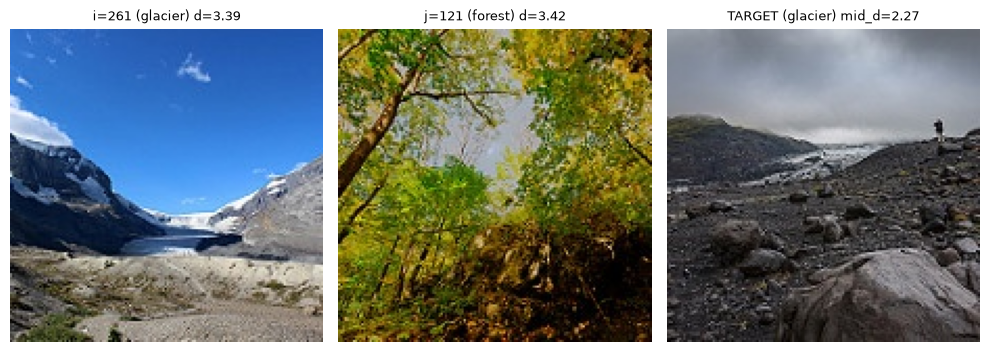


PATTERN B — equidistant across target (cross-basin ambiguity):


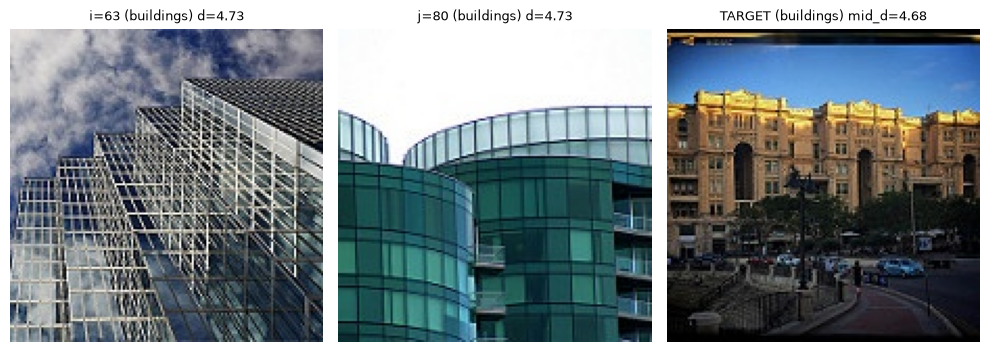

In [8]:
def show_query_with_midpoint_info(f):
    x_i, x_j, x_t = emb.X[f["i"]], emb.X[f["j"]], emb.X[f["target_idx"]]
    m = np.linalg.norm((x_i + x_j) / 2 - x_t)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    for ax, idx, title in zip(
        axes, [f["i"], f["j"], f["target_idx"]],
        [f"i={f['i']} ({f['class_i']}) d={f['d_i']:.2f}",
         f"j={f['j']} ({f['class_j']}) d={f['d_j']:.2f}",
         f"TARGET ({f['target_class']}) mid_d={m:.2f}"],
    ):
        img = Image.open(emb.paths[idx])
        ax.imshow(img); ax.set_title(title, fontsize=9); ax.axis('off')
    plt.tight_layout()
    plt.show()

close_mid_findings = [f for f, c in zip(findings, close_mid) if c]
far_mid_findings = [f for f, c in zip(findings, close_mid) if not c]

print("PATTERN A — target near midpoint (within-cluster near-duplicates):")
if close_mid_findings:
    show_query_with_midpoint_info(sorted(close_mid_findings, key=lambda f: f["confidence"])[0])

print("\nPATTERN B — equidistant across target (cross-basin ambiguity):")
if far_mid_findings:
    show_query_with_midpoint_info(sorted(far_mid_findings, key=lambda f: f["confidence"])[0])

In [9]:
class GammaCKLEngine3Way(GammaCKLEngine):
    """γ-CKL engine with 3-way oracle: pick i (y=0), pick j (y=1), both similar (y='B')."""
    def __init__(self, *args, both_threshold=0.15, **kwargs):
        super().__init__(*args, **kwargs)
        self.both_threshold = both_threshold

    def oracle_answer(self, i, j):
        if self.target_idx is None:
            raise RuntimeError("oracle_answer called without a target_idx")
        x_t = self.X[self.target_idx]
        d_i = np.linalg.norm(self.X[i] - x_t)
        d_j = np.linalg.norm(self.X[j] - x_t)
        if d_i == 0:
            return 0
        if d_j == 0:
            return 1
        p_i = (d_j ** self.gamma) / (d_i ** self.gamma + d_j ** self.gamma)
        asymmetry = abs(p_i - 0.5) * 2
        if asymmetry < self.both_threshold:
            return "B"
        return 0 if self.rng.random() < p_i else 1

    def apply_answer(self, y, status="clean"):
        i, j = self.propose_query()
        record = {
            "step": self.step, "i": int(i), "j": int(j),
            "y": y, "status": status,
        }
        self.used |= {i, j}
        self._pending_query = None

        if self.target_idx is not None and self.target_idx in (i, j) and y in (0, 1):
            self.step += 1
            self.done = True
            self.stop_reason = "in_query"
            return record

        eps = 1e-12
        d_i_all = np.linalg.norm(self.X - self.X[i], axis=1)
        d_j_all = np.linalg.norm(self.X - self.X[j], axis=1)
        d_i_g = d_i_all ** self.gamma
        d_j_g = d_j_all ** self.gamma
        denom = d_i_g + d_j_g + eps

        if y == "B":
            p_i_all = d_j_g / denom
            likelihood = 4.0 * p_i_all * (1.0 - p_i_all)
        elif y == 0:
            likelihood = d_j_g / denom
        elif y == 1:
            likelihood = d_i_g / denom
        else:
            likelihood = None

        if likelihood is not None:
            P_new = self.P * likelihood
            Z = P_new.sum()
            if Z > eps:
                self.P = P_new / Z

        self.step += 1
        if self.step >= self.max_queries:
            self.done = True
            self.stop_reason = "max_queries"
        return record

In [10]:
def run_2way(target_idx):
    seed = target_seed(target_idx)
    engine = GammaCKLEngine(X=emb.X, gamma=GAMMA, target_idx=int(target_idx),
                            seed=seed, max_queries=config.MAX_QUERIES)
    while not engine.done:
        i, j = engine.propose_query()
        y = engine.oracle_answer(i, j)
        engine.apply_answer(y, status="clean")
    return engine.step, engine.stop_reason, 0

def run_3way(target_idx, both_threshold=0.15):
    seed = target_seed(target_idx)
    engine = GammaCKLEngine3Way(X=emb.X, gamma=GAMMA, target_idx=int(target_idx),
                                seed=seed, max_queries=config.MAX_QUERIES,
                                both_threshold=both_threshold)
    n_both = 0
    while not engine.done:
        i, j = engine.propose_query()
        y = engine.oracle_answer(i, j)
        if y == "B":
            n_both += 1
        engine.apply_answer(y, status="clean")
    return engine.step, engine.stop_reason, n_both

print("=" * 70)
print("2-WAY vs 3-WAY γ-CKL — 100 targets")
print("=" * 70)

results = {"2way": [], "3way_15": [], "3way_20": [], "3way_25": []}
n_both_list = {"3way_15": [], "3way_20": [], "3way_25": []}

for target_idx in TARGET_INDICES:
    results["2way"].append(run_2way(target_idx)[0])
    for tau in [0.15, 0.20, 0.25]:
        key = f"3way_{int(tau*100)}"
        steps, _, nb = run_3way(target_idx, both_threshold=tau)
        results[key].append(steps)
        n_both_list[key].append(nb)

print(f"\n{'method':<15} {'mean':<7} {'median':<8} {'p95':<7} {'max':<6} {'avg both/run':<12}")
print("-" * 60)
for key in ["2way", "3way_15", "3way_20", "3way_25"]:
    arr = np.array(results[key])
    both_avg = np.mean(n_both_list.get(key, [0])) if key != "2way" else 0
    print(f"  {key:<13} {arr.mean():<7.1f} {np.median(arr):<8.1f} "
          f"{np.percentile(arr, 95):<7.1f} {arr.max():<6d} {both_avg:<12.1f}")

2-WAY vs 3-WAY γ-CKL — 100 targets

method          mean    median   p95     max    avg both/run
------------------------------------------------------------
  2way          13.5    11.0     28.1    50     0.0         
  3way_15       10.8    9.0      20.0    33     1.1         
  3way_20       10.2    9.0      17.0    29     1.4         
  3way_25       9.4     9.0      16.0    20     1.6         


target 402 (sea), 3-way τ=0.25
total steps: 7, stop_reason: in_query
trajectory: [(1, 371, 69, 0), (2, 261, 121, 1), (3, 189, 414, 1), (4, 441, 312, 0), (5, 493, 258, 0), (6, 420, 409, 1), (7, 402, 486, 0)]



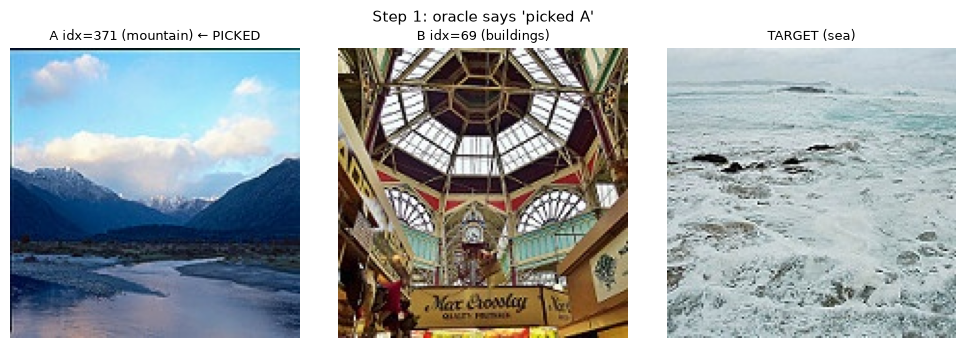

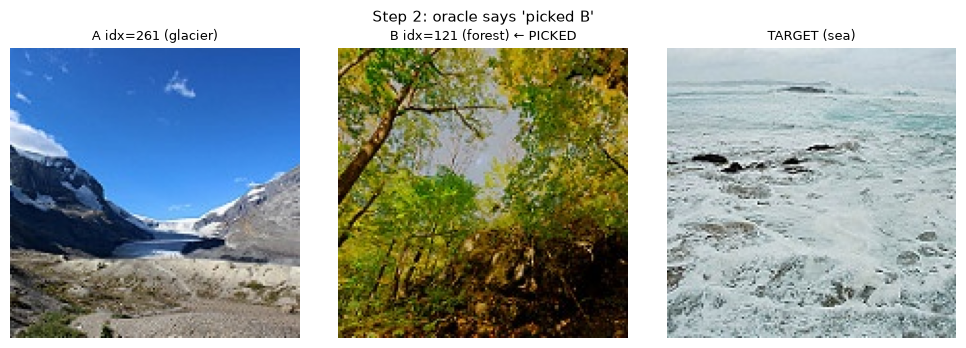

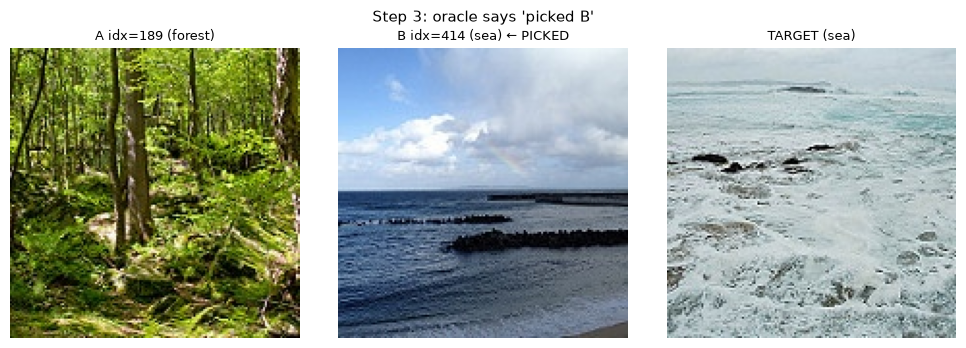

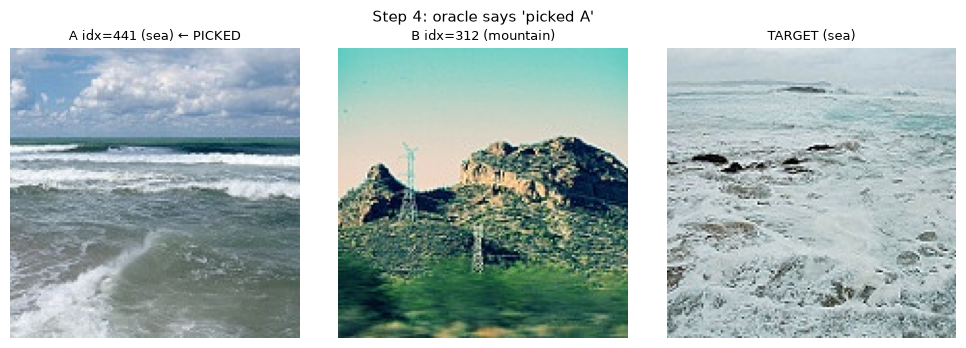

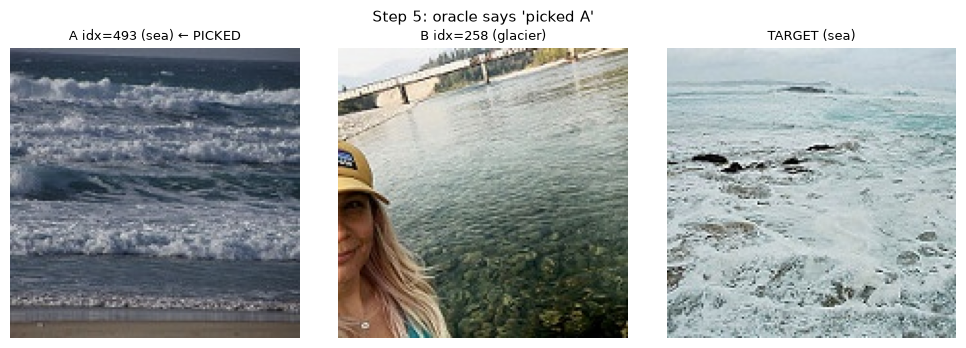

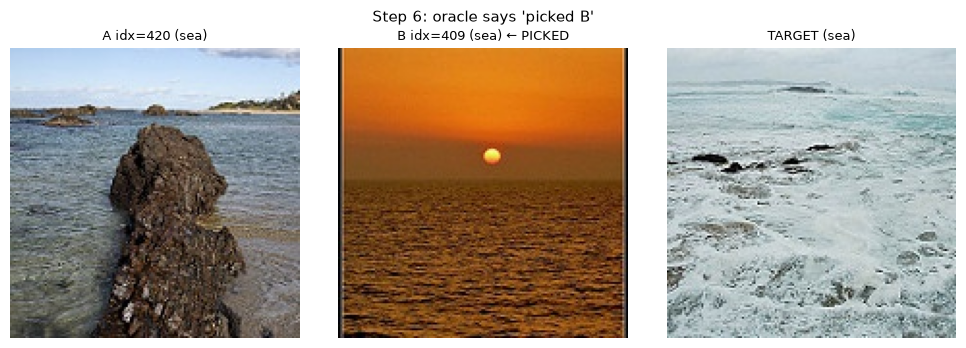

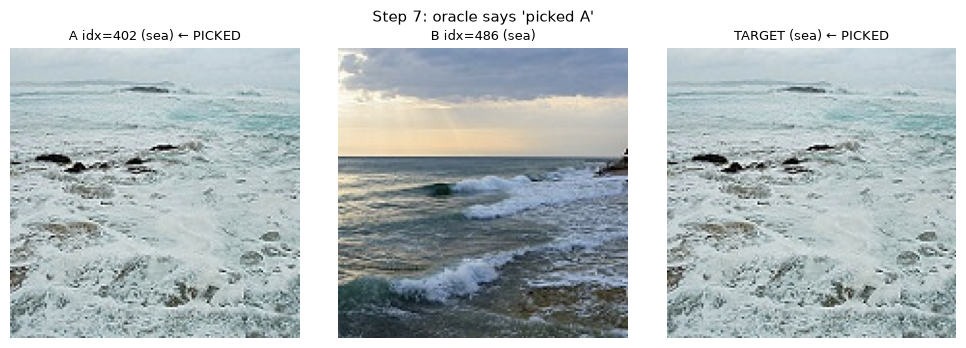

In [12]:
def trace_3way(target_idx, both_threshold=0.25):
    seed = target_seed(target_idx)
    engine = GammaCKLEngine3Way(
        X=emb.X, gamma=GAMMA,
        target_idx=int(target_idx), seed=seed,
        max_queries=config.MAX_QUERIES,
        both_threshold=both_threshold,
    )
    trajectory = []
    while not engine.done:
        i, j = engine.propose_query()
        y = engine.oracle_answer(i, j)
        trajectory.append((engine.step + 1, i, j, y))
        engine.apply_answer(y, status="clean")
    return trajectory, engine.step, engine.stop_reason


def show_step(target_idx, i, j, y, step):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    picked_idx = i if y == 0 else (j if y == 1 else None)
    for ax, idx, role in zip(
        axes, [i, j, target_idx],
        [f"A idx={i} ({emb.label(i)})",
         f"B idx={j} ({emb.label(j)})",
         f"TARGET ({emb.label(target_idx)})"],
    ):
        img = Image.open(emb.paths[idx])
        ax.imshow(img)
        marker = ""
        if idx == picked_idx and picked_idx is not None:
            marker = " ← PICKED"
        elif idx in (i, j) and y == "B":
            marker = " ← both similar"
        ax.set_title(f"{role}{marker}", fontsize=9)
        ax.axis('off')
    if y == "B":
        answer_str = "BOTH SIMILAR"
    else:
        answer_str = "picked A" if y == 0 else "picked B"
    plt.suptitle(f"Step {step}: oracle says '{answer_str}'", fontsize=11)
    plt.tight_layout()
    plt.show()


target_idx = 402

trajectory, total_steps, reason = trace_3way(target_idx, both_threshold=0.25)
print(f"target {target_idx} ({emb.label(target_idx)}), 3-way τ=0.25")
print(f"total steps: {total_steps}, stop_reason: {reason}")
print(f"trajectory: {trajectory}\n")

for step, i, j, y in trajectory:
    show_step(target_idx, i, j, y, step)